In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

df = pd.read_csv('retail_sales_dataset.csv')
print('Shape:', df.shape)
df.head()

Shape: (500, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,0,11/8/2023,C021,Female,64,Clothing,2,25,50
1,1,6/3/2023,C107,Female,58,Clothing,3,300,900
2,2,11/24/2023,C091,Male,44,Clothing,4,50,200
3,3,1/10/2023,C130,Female,33,Electronics,4,25,100
4,4,2/5/2023,C039,Female,40,Beauty,1,25,25


In [2]:
df.info()
print('\nNull values per column:')
print(df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    500 non-null    int64 
 1   Date              500 non-null    object
 2   Customer ID       500 non-null    object
 3   Gender            500 non-null    object
 4   Age               500 non-null    int64 
 5   Product Category  500 non-null    object
 6   Quantity          500 non-null    int64 
 7   Price per Unit    500 non-null    int64 
 8   Total Amount      500 non-null    int64 
dtypes: int64(5), object(4)
memory usage: 35.3+ KB

Null values per column:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate rows: 0


In [3]:
df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.to_period('M').astype(str)
df['Quarter'] = df['Date'].dt.to_period('Q').astype(str)
df['Age Group'] = pd.cut(df['Age'], bins=[17, 25, 35, 45, 55, 100],
                         labels=['18-25', '26-35', '36-45', '46-55', '56+'])
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount,Month,Quarter,Age Group
0,0,2023-11-08,C021,Female,64,Clothing,2,25,50,2023-11,2023Q4,56+
1,1,2023-06-03,C107,Female,58,Clothing,3,300,900,2023-06,2023Q2,56+
2,2,2023-11-24,C091,Male,44,Clothing,4,50,200,2023-11,2023Q4,36-45
3,3,2023-01-10,C130,Female,33,Electronics,4,25,100,2023-01,2023Q1,26-35
4,4,2023-02-05,C039,Female,40,Beauty,1,25,25,2023-02,2023Q1,36-45


In [5]:
num_cols = ['Age', 'Quantity', 'Price per Unit', 'Total Amount']
stats = df[num_cols].agg(['mean', 'median', 'std']).T
stats['mode'] = [df[c].mode()[0] for c in num_cols]
stats

,mean,median,std,mode
Age,39.962,40.0,13.586971,48
Quantity,2.572,3.0,1.115035,4
Price per Unit,175.410,50.0,189.802349,25
Total Amount,450.670,120.0,570.288751,100


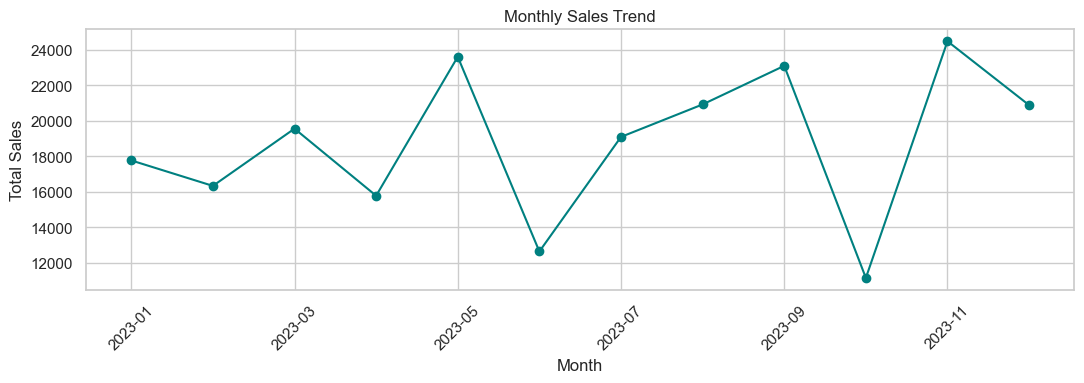

In [4]:
monthly = df.groupby('Month')['Total Amount'].sum()
plt.figure(figsize=(11, 4))
monthly.plot(marker='o', color='teal')
plt.title('Monthly Sales Trend'); plt.xlabel('Month'); plt.ylabel('Total Sales')
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

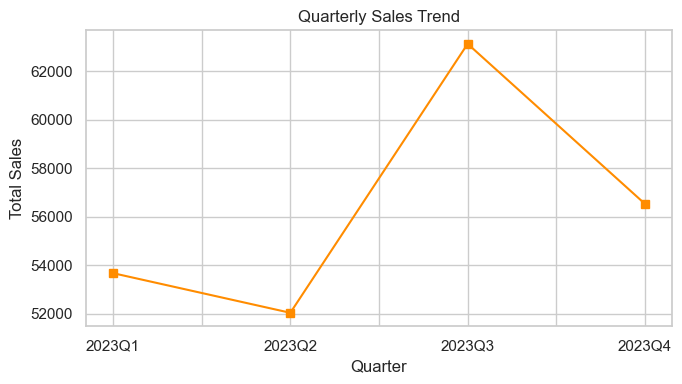

In [6]:
quarterly = df.groupby('Quarter')['Total Amount'].sum()
plt.figure(figsize=(7, 4))
quarterly.plot(marker='s', color='darkorange')
plt.title('Quarterly Sales Trend'); plt.ylabel('Total Sales')
plt.tight_layout(); plt.show()

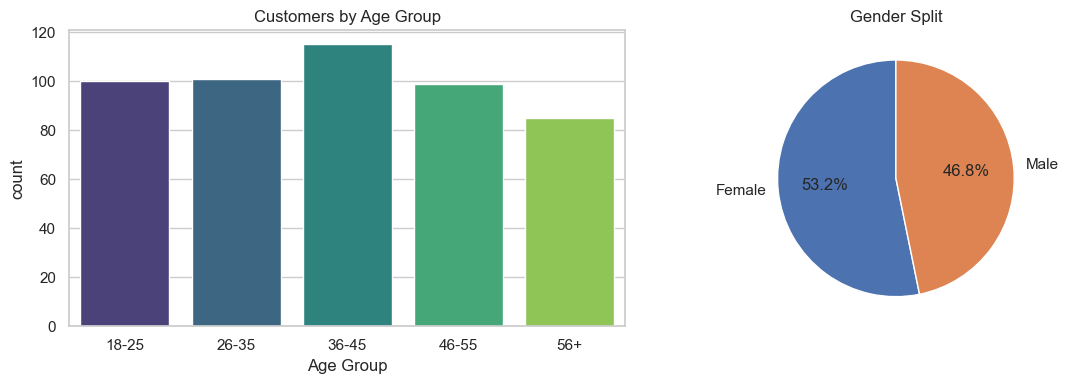

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x='Age Group', data=df, ax=ax[0], palette='viridis')
ax[0].set_title('Customers by Age Group')
df['Gender'].value_counts().plot.pie(autopct='%1.1f%%', ax=ax[1], startangle=90)
ax[1].set_title('Gender Split'); ax[1].set_ylabel('')
plt.tight_layout(); plt.show()

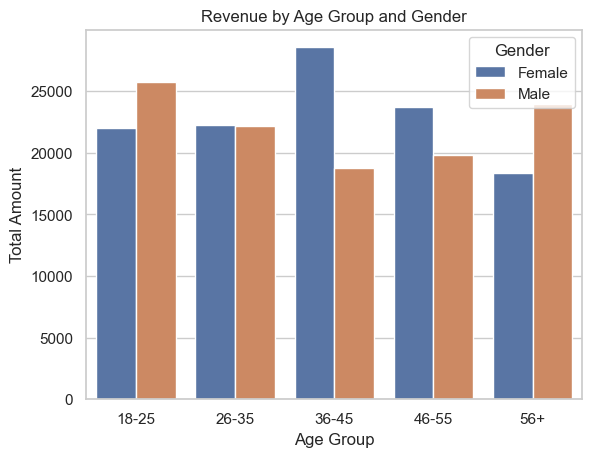

In [8]:
sns.barplot(x='Age Group', y='Total Amount', hue='Gender', data=df, estimator=sum, ci=None)
plt.title('Revenue by Age Group and Gender'); plt.show()

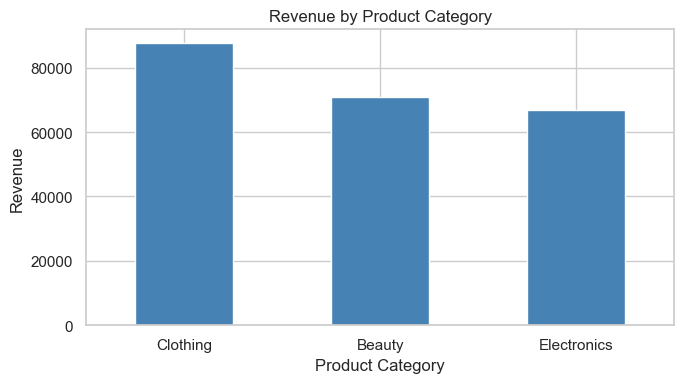

Product Category
Clothing       453
Electronics    419
Beauty         414
Name: Quantity, dtype: int64


In [9]:
cat_rev = df.groupby('Product Category')['Total Amount'].sum().sort_values(ascending=False)
cat_rev.plot(kind='bar', color='steelblue', figsize=(7, 4))
plt.title('Revenue by Product Category'); plt.ylabel('Revenue'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()
print(df.groupby('Product Category')['Quantity'].sum().sort_values(ascending=False))

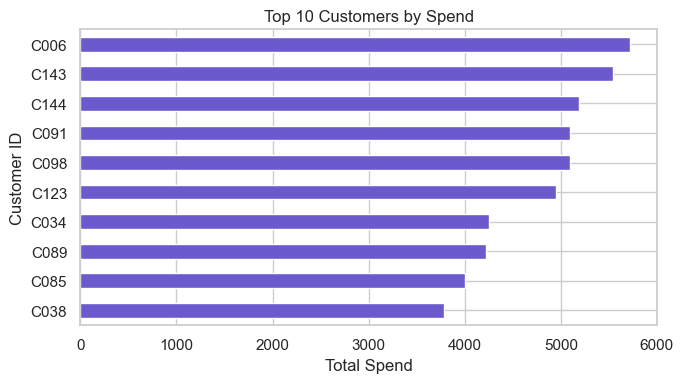

In [10]:
top_customers = df.groupby('Customer ID')['Total Amount'].sum().nlargest(10)
top_customers.plot(kind='barh', color='slateblue', figsize=(7, 4)).invert_yaxis()
plt.title('Top 10 Customers by Spend'); plt.xlabel('Total Spend')
plt.tight_layout(); plt.show()

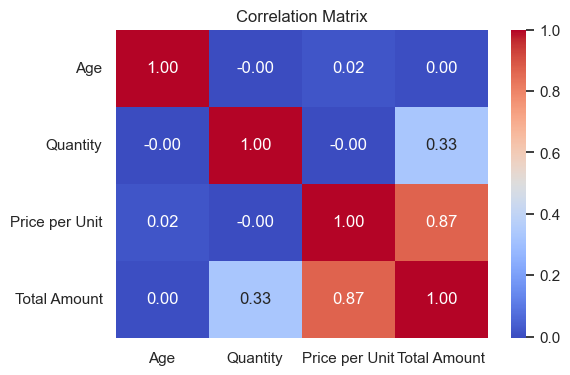

In [11]:
plt.figure(figsize=(6, 4))
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix'); plt.show()

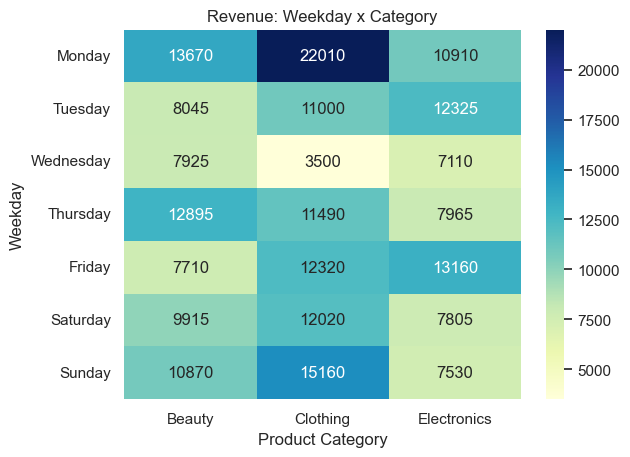

In [12]:
df['Weekday'] = df['Date'].dt.day_name()
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
pivot = df.pivot_table(index='Weekday', columns='Product Category',
                       values='Total Amount', aggfunc='sum').reindex(order)
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='YlGnBu')
plt.title('Revenue: Weekday x Category'); plt.show()